# Setup notebook

## Import modules

In [1]:
import numpy as np
import pandas as pd
from datetime import datetime
from datetime import timedelta
import matplotlib.pyplot as plt
from astropy.io import fits
import math
import os
import json
import glob
import pickle
import matplotlib.dates as mdates
from sunpy.coordinates import frames, get_horizons_coord
from matplotlib.lines import Line2D
import astropy.units as u
import seaborn as sns

save_plots = True
save_plot_paper_path = 'paper_plots/'

if not os.path.exists(save_plot_paper_path):
    os.makedirs(save_plot_paper_path)

In [2]:
def convert_time(time_data, format='%Y-%m-%dT%H:%MZ'):
    try:
        converted_time = datetime.strptime(time_data, format)
    except (ValueError, TypeError):
        converted_time = pd.NaT
    
    return converted_time

## Define colors and font sizes

In [3]:
geosphere_purple = '#701F80'
geosphere_green = '#75CC41'
geosphere_yellow = '#F9F200'
geosphere_orange = '#F29707'
my_pink = '#FF69B4'

legend_fontsize = 15
ticks_fontsize = 14
label_fontsize = 15

# Make Figure 1

**Load cleaned DONKI data and convert time from string to datetime.**

In [4]:
data_donki = 'STRUDL_Tracking_Analysis/data/DONKI_cme_analyses_matched.json'
donki_df = pd.read_json(data_donki)

time_columns = ['time21_5', 'submissionTime', 'earthArrivalTime', 'strudlFirstHItime']

for time_col in time_columns:
    donki_df[time_col] = donki_df[time_col].apply(lambda x: convert_time(x, '%Y-%m-%dT%H:%MZ'))

time_range = [datetime(2024,5,1), datetime(2025,4,30)]

donki_df_filtered = donki_df[(donki_df['time21_5'] >= time_range[0]) & (donki_df['time21_5'] <= time_range[1])]
donki_df_filtered = donki_df_filtered[donki_df_filtered['featureCode'] != 'TE']
donki_df_dedupe = donki_df_filtered.sort_values(by='featureCode', axis=0).drop_duplicates(subset='associatedActivityID')

**Plot total number of DONKI CMEs vs. DONKI CMEs with Earth arrival**

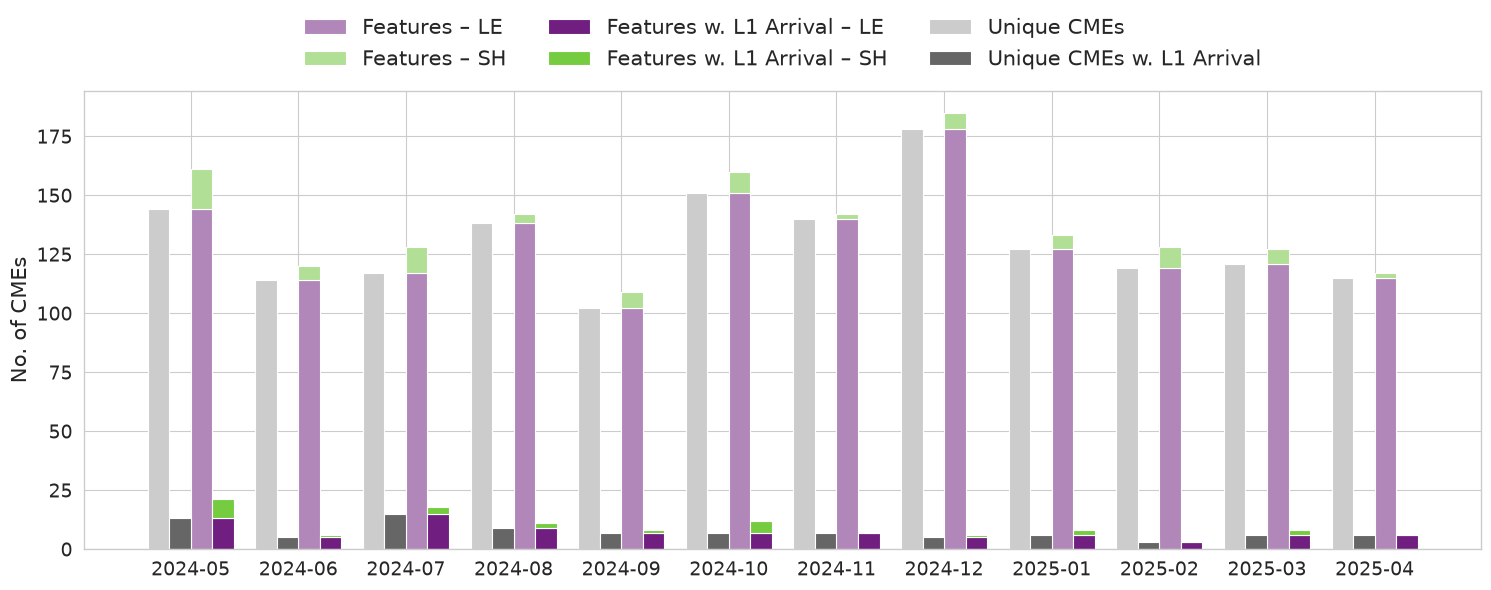

In [5]:
purple_palette = sns.light_palette(geosphere_purple, n_colors=3)
green_palette = sns.light_palette(geosphere_green, n_colors=3)


color_map = {
    ("Features",      "LE"): purple_palette[1],
    ("Features",      "SH"): green_palette[1],
    ("Features w. L1 Arrival", "LE"): purple_palette[2],
    ("Features w. L1 Arrival", "SH"): green_palette[2],
    ("Unique CMEs", "total"): '#CCCCCC',
    ("Unique CMEs w. L1 Arrival", "total"): '#666666'
}

# --- Prep ---
sns.set_theme(context="paper", style="whitegrid")

donki_df_filtered["month"] = donki_df_filtered["time21_5"].dt.to_period("M")
donki_df_dedupe["month"] = donki_df_dedupe["time21_5"].dt.to_period("M")

months = donki_df_filtered["month"].sort_values().unique()
month_strs = [str(m) for m in months]

cat_features = "Features"
cat_features_arrival = "Features w. L1 Arrival"
cat_unique_cmes = "Unique CMEs"
cat_unique_cmes_arrival = "Unique CMEs w. L1 Arrival"

all_cmes = (
    donki_df_filtered.groupby(["month", "featureCode"])
    .size()
    .reset_index(name="count")
    .assign(category="Features")
)
earth_cmes = (
    donki_df_filtered[donki_df_filtered["hasEarthArrival"]]
    .groupby(["month", "featureCode"])
    .size()
    .reset_index(name="count")
    .assign(category="Features w. L1 Arrival")
)

unique_all = (
    donki_df_dedupe.groupby("month")
    .size()
    .reset_index(name="count")
    .assign(category="Unique CMEs", featureCode="total")
)
unique_earth = (
    donki_df_dedupe[donki_df_dedupe["hasEarthArrival"]]
    .groupby("month")
    .size()
    .reset_index(name="count")
    .assign(category="Unique CMEs w. L1 Arrival", featureCode="total")
)

plot_df = pd.concat([all_cmes, earth_cmes, unique_all, unique_earth], ignore_index=True)
plot_df["month_str"] = plot_df["month"].astype(str)

# --- Plot ---
fig, ax = plt.subplots(figsize=(15, 6))

x = range(len(month_strs))
bar_width = 0.2
offsets = {
    "Unique CMEs":              -0.3,
    "Unique CMEs w. L1 Arrival":   -0.1,
    "Features":                   0.1,
    "Features w. L1 Arrival":     0.3,
}
bar_bottoms = {(cat, m): 0 for cat in offsets for m in month_strs}

for (category, feature), group in plot_df.groupby(["category", "featureCode"]):
    counts = dict(zip(group["month_str"], group["count"]))
    values = [counts.get(m, 0) for m in month_strs]
    bottoms = [bar_bottoms[(category, m)] for m in month_strs]
    x_positions = [i + offsets[category] for i in x]

    if feature == "total":
        lb = f"{category}"
    else:
        lb = f"{category} – {feature}"

    ax.bar(
        x_positions,
        values,
        width=bar_width,
        bottom=bottoms,
        color=color_map[(category, feature)],
        label=lb,
    )

    for i, m in enumerate(month_strs):
        bar_bottoms[(category, m)] += values[i]

ax.set_xticks(list(x))
ax.set_xticklabels(month_strs, rotation=0, ha="center")
ax.tick_params(axis='both', which='major', labelsize=ticks_fontsize)
#ax.set_xlabel("Date")
ax.set_ylabel("No. of CMEs", fontsize=label_fontsize)
#ax.set_title("Total Events vs DONKI CMEs w. L1 Arrivals by Month")
ax.legend(title="", bbox_to_anchor=(0.5, 1.2), loc="upper center", ncols=3, frameon=False, fontsize=legend_fontsize)
plt.tight_layout()


if save_plots:
    plt.savefig(save_plot_paper_path+'donki_stats.pdf', bbox_inches='tight')
plt.show()


In [6]:
# print(f"SH total: {plot_df[(plot_df['featureCode'] == 'SH') & (plot_df['category'] == 'DONKI CMEs')]['count'].sum()}")
# print(f"LE total: {plot_df[(plot_df['featureCode'] == 'LE') & (plot_df['category'] == 'DONKI CMEs')]['count'].sum()}")
# print(f"Unique total: {plot_df[(plot_df['featureCode'] == 'total') & (plot_df['category'] == 'Unique DONKI CMEs')]['count'].sum()}")

# print(f"SH w. L1 Arrival: {plot_df[(plot_df['featureCode'] == 'SH') & (plot_df['category'] == cat_features_arrival)]['count'].sum()}")
# print(f"LE w. L1 Arrival: {plot_df[(plot_df['featureCode'] == 'LE') & (plot_df['category'] == 'DONKI CMEs w. L1 Arrival')]['count'].sum()}")
# print(f"Unique w. L1 Arrival: {plot_df[(plot_df['featureCode'] == 'total') & (plot_df['category'] == 'Unique CMEs w. L1 Arrival')]['count'].sum()}")

# Make Figure 4

**Load STRUDL segmentation results**

In [7]:
strudl_segmentation_path = 'STRUDL/segmentation_dictionary_mean_45_2024_05_01_2025_05_01.npy'
strudl_seg = np.load(strudl_segmentation_path, allow_pickle=True).item()

In [8]:
def get_corresponding_rundifs(segmentation_times, rundif_path='HI_Data_Processing/stereo_processed/running_difference/data/A/'):

    # get times for this CME
    image_list = [f"{rundif_path}{tim.strftime('%Y%m%d_%H%M%S')[:8]}/science/hi_1/{tim.strftime('%Y%m%d_%H%M%S')}_1bh1A.fts" for tim in segmentation_times]
    
    # load the fts files if they exist, otherwise skip
    image_data = []
    header_data = []
    for image_path in image_list:
        try:
            with fits.open(image_path) as hdul:
                image_data.append(hdul[0].data)
                header_data.append(hdul[0].header)
        except FileNotFoundError:
            image_data.append(np.zeros((1024, 1024)))  # placeholder for missing image
            header_data.append(None)  # placeholder for missing header
            print(f"File not found: {image_path}")
            continue
    
    return image_data, header_data

**Plot STRUDL tracking results over corresponding running difference images**

In [29]:
rundif_path = 'HI_Data_Processing/stereo_processed/running_difference/data/A/'
chosen_times = [datetime(2024,8,20,15,58,11), datetime(2024,7,23,11,18,11)]

for plot_time in chosen_times:
    for key in strudl_seg.keys():
        if plot_time not in strudl_seg[key]['times']:
            continue
        else:
            image_data, header_data = get_corresponding_rundifs(strudl_seg[key]['times'], rundif_path)
            total_images = len(strudl_seg[key]['times'])
            num_images_per_fig = 8
            num_figs = math.floor(total_images / num_images_per_fig)

            num_cols = 4
            num_rows = 2
            figsize = (num_cols * 2, num_rows * 2)

            fac_contrast = 0.25


            for i in range(num_figs):
                fig, axes = plt.subplots(num_rows, num_cols, figsize=figsize)
                fig.subplots_adjust(wspace=0, hspace=0, left=0, right=1, top=1, bottom=0)
                
                for j in range(num_images_per_fig):
                    img_index = i * num_images_per_fig + j

                    if img_index >= total_images:
                        break
                    
                    ax = axes[j // num_cols, j % num_cols]

                    ax.imshow(np.flipud(image_data[img_index]),
                            aspect='equal',
                            cmap='gray',
                            vmin=np.nanmedian(image_data[img_index])-fac_contrast*np.nanstd(image_data[img_index]),
                            vmax=np.nanmedian(image_data[img_index])+fac_contrast*np.nanstd(image_data[img_index]),
                            extent=(0, image_data[img_index].shape[1], image_data[img_index].shape[0], 0),
                            interpolation='none')
                    
                    ax.axis('off')

                    xcoords = strudl_seg[key]['cme_front_pixels'][img_index][1]
                    ycoords = strudl_seg[key]['cme_front_pixels'][img_index][0]

                    if image_data[img_index].shape[0] != 128:
                        xcoords = np.clip(xcoords*8.0, 0, image_data[img_index].shape[0]-1).astype(int)
                        ycoords = np.clip(ycoords*8.0, 0, image_data[img_index].shape[0]-1).astype(int)

                    ax.scatter(xcoords, image_data[img_index].shape[0]-ycoords, s=10, color=geosphere_yellow, alpha=0.8, marker='x')
                    ax.set_frame_on(False)
                
                if not os.path.exists(save_plot_paper_path):
                    os.makedirs(save_plot_paper_path)

                if save_plots:
                    if strudl_seg[key]['times'][img_index-num_images_per_fig] == plot_time:
                        plt.savefig(save_plot_paper_path+'strudl_' + datetime.strftime(strudl_seg[key]['times'][img_index-num_images_per_fig], '%Y%m%d_%H%M%S') + '.pdf', dpi=300, bbox_inches='tight',pad_inches=0.0)
                        plt.close()

                    else:
                        plt.close()

# Make Table 1

In [10]:
elevo_results = 'ELEvo/data/elevo_results_20240501_20250501.json'
elevo_results_df = pd.read_json(elevo_results)
elevo_results_df.rename(columns={'L1_ist_obs': 'L1_ist_obs [UT]'}, inplace=True)

# convert all times to datetime objects
time_columns = ['L1_ist_obs [UT]', 'tinit [UT]','arrival_time_min [UT]', 'arrival_time_max [UT]', 'arrival_time [UT]']
for time_col in time_columns:
    elevo_results_df[time_col] = elevo_results_df[time_col].apply(lambda x: convert_time(x, '%Y-%m-%dT%H:%MZ'))

elevo_results_df['time_axis [UT]'] = elevo_results_df['time_axis [UT]'].apply(lambda x: [convert_time(y, '%Y-%m-%dT%H:%MZ') for y in x])
corrected_results = 'STRUDL_Tracking_Analysis/data/mean_45_2024_05_01_2025_05_01_strudl_tracks_corrected.json'
corrected_results_df = pd.read_json(corrected_results)
corrected_results_df['time'] = corrected_results_df['time'].apply(lambda x: [convert_time(y, '%Y-%m-%dT%H:%M:%S.%f') for y in x])

uncorrected_results = 'STRUDL_Tracking_Analysis/data/mean_45_2024_05_01_2025_05_01_strudl_tracks.json'
uncorrected_results_df = pd.read_json(uncorrected_results)
uncorrected_results_df['time'] = uncorrected_results_df['time'].apply(lambda x: [convert_time(y, '%Y-%m-%dT%H:%M:%S.000') for y in x])

In [11]:
elevohi_results_uncorrected = 'ELEvoHI/results/elevohi_ensembles_results_raw.json'
elevohi_results_uncorrected_df = pd.read_json(elevohi_results_uncorrected)

elevohi_results_corrected = 'ELEvoHI/results/elevohi_ensembles_results_cleaned.json'
elevohi_results_corrected_df = pd.read_json(elevohi_results_corrected)

for time_col in time_columns:
    elevohi_results_uncorrected_df[time_col] = elevohi_results_uncorrected_df[time_col].apply(lambda x: convert_time(x, '%Y-%m-%dT%H:%MZ'))
    elevohi_results_corrected_df[time_col] = elevohi_results_corrected_df[time_col].apply(lambda x: convert_time(x, '%Y-%m-%dT%H:%MZ'))

In [12]:
max_fitted_uncorrected_failed = []
max_fitted_uncorrected_succeeded = []
for row_num, row_results in uncorrected_results_df.iterrows():

    if row_results['cmeID_strudl'] is not None:
        corresponding_data = elevohi_results_uncorrected_df[(elevohi_results_uncorrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (elevohi_results_uncorrected_df['cmeID_strudl'] == row_results['cmeID_strudl']) &
                                                            (elevohi_results_uncorrected_df['featureCode'] == row_results['featureCode'])]
    else:
        corresponding_data = elevohi_results_uncorrected_df[(elevohi_results_uncorrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (pd.isna(elevohi_results_uncorrected_df['cmeID_strudl'])) &
                                                            (elevohi_results_uncorrected_df['featureCode'] == row_results['featureCode'])]
    
    if corresponding_data.empty:
        max_fitted_uncorrected_failed.append(np.nanmax(row_results['elongation']))
    else:
        max_fitted_uncorrected_succeeded.append(np.nanmax(row_results['elongation']))

max_fitted_corrected_failed = []
max_fitted_corrected_succeeded = []
for row_num, row_results in corrected_results_df.iterrows():
    
    if row_results['cmeID_strudl'] is not None:
        corresponding_data = elevohi_results_corrected_df[(elevohi_results_corrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (elevohi_results_corrected_df['cmeID_strudl'] == row_results['cmeID_strudl']) &
                                                            (elevohi_results_corrected_df['featureCode'] == row_results['featureCode'])]
    else:
        corresponding_data = elevohi_results_corrected_df[(elevohi_results_corrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (pd.isna(elevohi_results_corrected_df['cmeID_strudl'])) &
                                                            (elevohi_results_corrected_df['featureCode'] == row_results['featureCode'])]
    
    if corresponding_data.empty:
        max_fitted_corrected_failed.append(np.nanmax(row_results['elongation']))
    else:
        max_fitted_corrected_succeeded.append(np.nanmax(row_results['elongation']))

In [13]:
uncorrected_max_el = np.nanmean(uncorrected_results_df['elongation'].apply(lambda x: max(x) if isinstance(x, list) else np.nan))
corrected_max_el = np.nanmean(corrected_results_df['elongation'].apply(lambda x: max(x) if isinstance(x, list) else np.nan))

uncorrected_delta_time_215 = np.nanmean(uncorrected_results_df.apply(lambda row: (row['time'][0] - datetime.strptime(row['time_21_5Rs'], '%Y-%m-%dT%H:%MZ')).total_seconds() / 3600.0 if isinstance(row['time'], list) and len(row['time']) > 0 and pd.notnull(datetime.strptime(row['time_21_5Rs'], '%Y-%m-%dT%H:%MZ')) else np.nan, axis=1))
corrected_delta_time_215 = np.nanmean(corrected_results_df.apply(lambda row: (row['time'][0] - datetime.strptime(row['time_21_5Rs'], '%Y-%m-%dT%H:%MZ')).total_seconds() / 3600.0 if isinstance(row['time'], list) and len(row['time']) > 0 and pd.notnull(datetime.strptime(row['time_21_5Rs'], '%Y-%m-%dT%H:%MZ')) else np.nan, axis=1))

# Make Figure 8

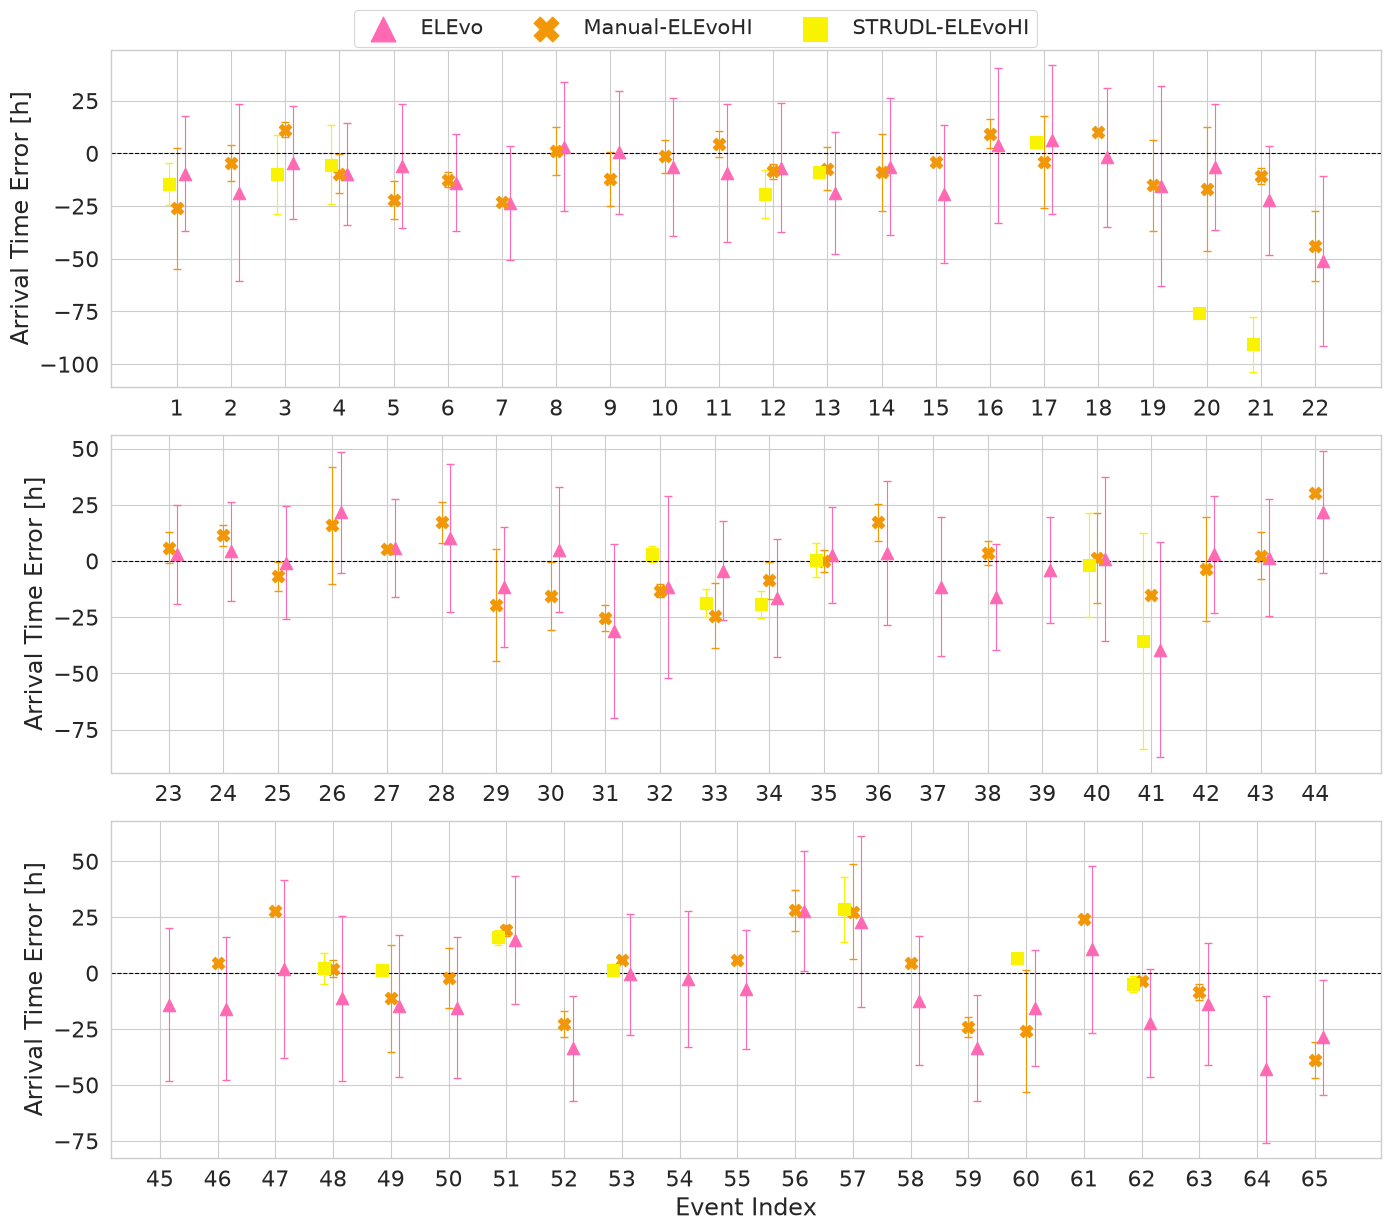

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

elevohi_uncorrected_label = "STRUDL-ELEvoHI"
elevohi_corrected_label = "Manual-ELEvoHI"
elevo_label = "ELEvo"
# --- Colors and styles ---
marker_styles = {
    elevohi_uncorrected_label: dict(marker="s", color=geosphere_yellow,  label=elevohi_uncorrected_label),
    elevohi_corrected_label:   dict(marker="X", color=geosphere_orange,  label=elevohi_corrected_label),
    elevo_label:               dict(marker="^", color=my_pink,           label=elevo_label),
}
offsets = {
    elevohi_uncorrected_label: -0.15,
    elevohi_corrected_label:    0.0,
    elevo_label:                0.15,
}

# --- Prep ---
sns.set_theme(context="paper", style="whitegrid")

def prepare(df, name):
    df = df.copy()
    df["label"] = (
        df["cmeID_elevo"].astype(str) + " / " +
        df["featureCode"].astype(str)
    )
    df["err_mean"] = (df["L1_ist_obs [UT]"] - df["arrival_time [UT]"]).dt.total_seconds() / 3600
    df["err_min"]  = (df["L1_ist_obs [UT]"] - df["arrival_time_min [UT]"]).dt.total_seconds() / 3600
    df["err_max"]  = (df["L1_ist_obs [UT]"] - df["arrival_time_max [UT]"]).dt.total_seconds() / 3600
    df = df.dropna(subset=["err_mean", "err_min", "err_max"])
    df["source"] = name
    df["tinit [UT]"] = df["tinit [UT]"].dt.strftime('%Y-%m-%dT%H:%MZ')
    return df[["label", "err_mean", "err_min", "err_max", "tinit [UT]", "source"]]

dfs = pd.concat([
    prepare(elevohi_results_uncorrected_df, elevohi_uncorrected_label),
    prepare(elevohi_results_corrected_df,   elevohi_corrected_label),
    prepare(elevo_results_df,               elevo_label),
], ignore_index=True)

dfs = dfs.sort_values(by=["tinit [UT]"], axis=0).reset_index(drop=True)
# All unique labels in order of first appearance
all_labels = list(dict.fromkeys(dfs["label"]))
label_to_x = {l: i for i, l in enumerate(all_labels)}

label_table = pd.DataFrame({
    "index": range(1, len(all_labels) + 1),
    "label": all_labels,
})
#label_table.to_csv(save_plot_paper_path+'Figure_8_legend.csv', index=False)

# --- Split evenly across 3 subplots ---
n = len(all_labels)
split1 = n // 3 + (1 if n % 3 > 0 else 0)   # 24
split2 = split1 + n // 3 + (1 if n % 3 > 1 else 0)  # 48

subsets = [
    all_labels[:split1],
    all_labels[split1:split2],
    all_labels[split2:],
]

# --- Plot ---
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for ax, subset in zip(axes, subsets):
    subset_dfs = dfs[dfs["label"].isin(subset)]

    for source, group in subset_dfs.groupby("source"):
        style = marker_styles[source]
        offset = offsets[source]
        x_pos = [label_to_x[l] + offset for l in group["label"]]

        ax.errorbar(
            x_pos, group["err_mean"],
            yerr=[np.abs(group["err_mean"] - group["err_min"]),
                  np.abs(group["err_max"] - group["err_mean"])],
            fmt="none", color=style["color"], capsize=3, linewidth=0.8,
        )
        ax.scatter(
            x_pos, group["err_mean"],
            marker=style["marker"], color=style["color"],
            label=style["label"], zorder=3, s=80,
        )

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xticks([label_to_x[l] for l in subset])
    ax.set_xticklabels(
        [label_to_x[l] + 1 for l in subset],
        rotation=0, ha="center", fontsize=ticks_fontsize+2,
    )
    ax.tick_params(axis='y', labelsize=ticks_fontsize+2)
    ax.set_ylabel("Arrival Time Error [h]", fontsize=label_fontsize+2)

axes[2].set_xlabel("Event Index", fontsize=label_fontsize+2)

handles, labels_leg = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_leg, title="", bbox_to_anchor=(0.5, 1.03),
           loc="upper center", ncols=3, frameon=True, fontsize=legend_fontsize, markerscale=2)

plt.tight_layout()
if save_plots:
    plt.savefig(save_plot_paper_path+'comparison_all_pipelines.pdf', bbox_inches='tight')
plt.show()

In [15]:
mean_abs_dt_elevo = np.nanmean(np.abs(elevo_results_df["arrival_time [UT]"] - elevo_results_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
mean_abs_dt_elevohi_uncorrected = np.nanmean(np.abs(elevohi_results_uncorrected_df["arrival_time [UT]"] - elevohi_results_uncorrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
mean_abs_dt_elevohi_corrected = np.nanmean(np.abs(elevohi_results_corrected_df["arrival_time [UT]"] - elevohi_results_corrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)

mean_abs_dt_elevo_max = np.nanmean(np.abs(elevo_results_df["arrival_time_max [UT]"] - elevo_results_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
mean_abs_dt_elevo_min = np.nanmean(np.abs(elevo_results_df["arrival_time_min [UT]"] - elevo_results_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)

mean_abs_dt_elevohi_uncorrected_max = np.nanmean(np.abs(elevohi_results_uncorrected_df["arrival_time_max [UT]"] - elevohi_results_uncorrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
mean_abs_dt_elevohi_uncorrected_min = np.nanmean(np.abs(elevohi_results_uncorrected_df["arrival_time_min [UT]"] - elevohi_results_uncorrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)

mean_abs_dt_elevohi_corrected_max = np.nanmean(np.abs(elevohi_results_corrected_df["arrival_time_max [UT]"] - elevohi_results_corrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
mean_abs_dt_elevohi_corrected_min = np.nanmean(np.abs(elevohi_results_corrected_df["arrival_time_min [UT]"] - elevohi_results_corrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)


In [16]:
std_mean_abs_dt_elevo = np.nanstd(np.abs(elevo_results_df["arrival_time [UT]"] - elevo_results_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
std_mean_abs_dt_elevohi_uncorrected = np.nanstd(np.abs(elevohi_results_uncorrected_df["arrival_time [UT]"] - elevohi_results_uncorrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
std_mean_abs_dt_elevohi_corrected = np.nanstd(np.abs(elevohi_results_corrected_df["arrival_time [UT]"] - elevohi_results_corrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)

std_mean_abs_dt_elevo_max = np.nanstd(np.abs(elevo_results_df["arrival_time_max [UT]"] - elevo_results_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
std_mean_abs_dt_elevo_min = np.nanstd(np.abs(elevo_results_df["arrival_time_min [UT]"] - elevo_results_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
std_mean_abs_dt_elevohi_uncorrected_max = np.nanstd(np.abs(elevohi_results_uncorrected_df["arrival_time_max [UT]"] - elevohi_results_uncorrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)

std_mean_abs_dt_elevohi_uncorrected_min = np.nanstd(np.abs(elevohi_results_uncorrected_df["arrival_time_min [UT]"] - elevohi_results_uncorrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
std_mean_abs_dt_elevohi_corrected_max = np.nanstd(np.abs(elevohi_results_corrected_df["arrival_time_max [UT]"] - elevohi_results_corrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)
std_mean_abs_dt_elevohi_corrected_min = np.nanstd(np.abs(elevohi_results_corrected_df["arrival_time_min [UT]"] - elevohi_results_corrected_df["L1_ist_obs [UT]"]).dt.total_seconds() / 3600)

# Make Figure 9

In [17]:
AU_in_km = u.au.to(u.km)
RSun_in_km = u.R_sun.to(u.km)

def load_jplot(path, instrument, ftpsc, bflag, start, end, jp_name):

    savepath_jplot = os.path.join(path, 'jplot', ftpsc, bflag, instrument, str(start[:4]), 'plots')
    savepath_param = os.path.join(path, 'jplot', ftpsc, bflag, instrument, str(start[:4]), 'params')
    
    instrument_name = 'hi1' if instrument == 'hi_1' else 'hi2'

    jplot_name = f"jplot_{instrument_name}_{start}_{end}_{ftpsc}_{bflag[0]}"
    param_fil = glob.glob(f"{savepath_param}/{jplot_name}_params.pkl")[0]
    plot_fil = glob.glob(f"{savepath_jplot}/{jplot_name}.pkl")[0]
    
    
    with open(param_fil, 'rb') as f:
        t_beg, t_end, e_beg, e_end = pickle.load(f)

    with open(plot_fil, 'rb') as f:
        img_rescale, orig = pickle.load(f)

    return img_rescale, orig, t_beg, t_end, e_beg, e_end

def plot_jplot_on_axis(
    ax,
    start,
    end,
    time_elon_elevo,
    time_elon_elevohi,
    elevo_elon_key='elongation_apex [°]',
    elevohi_elon_key='elongation_apex_tracked [°]',
):
    
    print(f'Loading J-plot for {start} to {end}...')
    try:
        # img_rescale, orig, t_beg, t_end, e_beg, e_end = load_jplot(
        #     output_dir, instrument, sc, data_flag, start, end, jp_name
        # )

        jplot_test_path = f'HI_Data_Processing/stereo_processed/jplots_pickles/{start}_hi_1.p'
        jplot_test = pd.read_pickle(jplot_test_path)

        t_beg = jplot_test['dates'][0]
        t_end = jplot_test['dates'][-1]
        e_beg = jplot_test['elongations'][0]
        e_end = jplot_test['elongations'][-1]
        jplot_nonmedian = jplot_test['data']
        img_rescale = np.median(jplot_nonmedian,1).T
        orig = jplot_test['origin']
        
    except Exception:
        ax.text(0.5, 0.5, 'No J-plot found',
                ha='center', va='center', transform=ax.transAxes)
        ax.axis('off')
        return

    # ---- prep image
    img = img_rescale.astype(float)
    vmin = np.nanmedian(img) - 0.25 * np.nanstd(img)
    vmax = np.nanmedian(img) + 0.25 * np.nanstd(img)

    cadence = 40.0  # minutes (HI-1)

    extent = [
        mdates.date2num(t_beg - timedelta(minutes=cadence / 2)),
        mdates.date2num(t_end + timedelta(minutes=cadence / 2)),
        e_beg,
        e_end
    ]

    ax.imshow(
        img,
        cmap='gray',
        aspect='auto',
        vmin=vmin,
        vmax=vmax,
        interpolation='none',
        origin=orig,
        extent=extent
    )

    # ---- overlay tracks

    alpha_vals_elevo = [0.8, 0.4, 0.4]

        
    for i in range(np.shape(time_elon_elevo[elevo_elon_key])[1]):
        ax.plot(
            time_elon_elevo['time_axis [UT]'],
            np.array(time_elon_elevo[elevo_elon_key])[:, i],
            color=my_pink,
            alpha=alpha_vals_elevo[i],
            lw=2
        )

    ax.scatter(
        time_elon_elevohi['time_apex_tracked [UT]'],
        time_elon_elevohi[elevohi_elon_key],
        color=geosphere_orange,
        marker='X',
        s=40,
        alpha=0.8
    )

    ax.set_xlim(
        np.array(time_elon_elevohi['time_apex_tracked [UT]']).min() - timedelta(minutes=6*60),
        np.array(time_elon_elevohi['time_apex_tracked [UT]']).max() + timedelta(minutes=6*60)
    )

    # ---- axis formatting (compact)
    ax.set_ylim(e_beg, 20)

    ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
    ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=range(0, 24, 6)))

    ax.tick_params(axis='both', labelsize=ticks_fontsize)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(False)

def convert_time_columns_to_datetime(params_array, time_columns):
    for param in params_array:
        for col in time_columns:
            if col in param:
                if type(param[col]) is list or type(param[col]) is np.ndarray:
                    param[col] = np.array([datetime.strptime(t, '%Y-%m-%dT%H:%MZ') for t in param[col]])
                else:
                    try:
                        param[col] = datetime.strptime(param[col], '%Y-%m-%dT%H:%MZ')
                    except Exception:
                        param[col] = np.nan
                        
    return params_array

def main(elevohi_path, elevohi_like_elevo_path, elevo_path, dbmplot_save_directory, chosen_events):

    elevohi_all_params = np.array(json.load(open(elevohi_path, 'r')))
    elevohi_all_params_like_elevo = np.array(json.load(open(elevohi_like_elevo_path, 'r')))
    elevo_all_params = np.array(json.load(open(elevo_path, 'r')))

    list_of_cme_ids = set([elevohi_all_params[i]['cmeID_elevo'] for i in range(len(elevohi_all_params))])

    # convert all times to datetime objects
    time_columns = ['L1_ist_obs [UT]','tinit [UT]','arrival_time [UT]','time_axis [UT]','time_apex_tracked [UT]', 'arrival_time_min [UT]', 'arrival_time_max [UT]']

    elevohi_all_params = convert_time_columns_to_datetime(elevohi_all_params, time_columns)
    elevohi_all_params_like_elevo = convert_time_columns_to_datetime(elevohi_all_params_like_elevo, time_columns)
    elevo_all_params = convert_time_columns_to_datetime(elevo_all_params, time_columns)

    for sub_num, elevo_sub in enumerate(elevo_all_params):

        corresponding_elevohi = elevohi_all_params[[(elevohi_all_params[i]['cmeID_elevo'] == elevo_sub['cmeID_elevo']) and (elevohi_all_params[i]['featureCode'] == elevo_sub['featureCode']) for i in range(len(elevohi_all_params))]]

        if len(corresponding_elevohi) == 0:
            is_arrival = np.nan
            dt = np.nan

        else:
            is_arrival = corresponding_elevohi[0]['L1_ist_obs [UT]']
            dt = (elevo_sub['arrival_time [UT]'] - is_arrival).total_seconds()/3600
        
        elevo_all_params[sub_num]['L1_ist_obs [UT]'] = is_arrival
        elevo_all_params[sub_num]['dt [h]'] = dt

    for sub_num, elevohi_sub in enumerate(elevohi_all_params_like_elevo):
        corresponding_elevohi = elevohi_all_params[[elevohi_all_params[i]['cmeID_elevo'] == elevohi_sub['cmeID_elevo'] for i in range(len(elevohi_all_params))]]
        corresponding_elevo = elevo_all_params[[elevo_all_params[i]['cmeID_elevo'] == elevohi_sub['cmeID_elevo'] for i in range(len(elevo_all_params))]]
        if len(corresponding_elevohi) == 0:
            is_arrival = np.nan
            dt = np.nan
        
        else:
            is_arrival = corresponding_elevohi[0]['L1_ist_obs [UT]']
            dt = (elevohi_sub['arrival_time [UT]'] - is_arrival).total_seconds()/3600
        
        elevohi_all_params_like_elevo[sub_num]['L1_ist_obs [UT]'] = is_arrival
        elevohi_all_params_like_elevo[sub_num]['dt [h]'] = dt
        elevohi_all_params_like_elevo[sub_num]['latitude [°]'] = corresponding_elevo[0]['latitude [°]']

    color_elevo = my_pink
    color_hi = 'black'
    marker_hi = 'o'
    rsun_lim = 220

    comparison_type = 'ELEvoHI (like ELEvo)'
    #list_of_cme_ids = ['2024-05-13T09:12:00-CME-001']

    cmap_res = plt.get_cmap("jet", 15)
    cmap_linsp = np.round(np.linspace(0, 1.5, 16),1)

    residual_to_color = {res: cmap_res(i) for i, res in enumerate(cmap_linsp)}
    
    for cme_id in list_of_cme_ids:
        elevohi_cmes_fcode = elevohi_all_params[[(elevohi_all_params[i]['cmeID_elevo'] == cme_id) for i in range(len(elevohi_all_params))]]

        fcodes = set([elevohi_cmes_fcode[i]['featureCode'] for i in range(len(elevohi_cmes_fcode))])

        for fcode in fcodes:
            if cme_id + '_' + fcode not in chosen_events:
                print(cme_id + '_' + fcode + ' not in chosen events, skipping...')
                continue

            elevohi_cmes = elevohi_cmes_fcode[[elevohi_cmes_fcode[i]['featureCode'] == fcode for i in range(len(elevohi_cmes_fcode))]]

            if comparison_type == 'ELEvoHI (like ELEvo)':
                elevo_cmes = elevohi_all_params_like_elevo[[(elevohi_all_params_like_elevo[i]['cmeID_elevo'] == cme_id) and (elevohi_all_params_like_elevo[i]['featureCode'] == fcode) for i in range(len(elevohi_all_params_like_elevo))]][0]
            else:
                elevo_cmes = elevo_all_params[[(elevo_all_params[i]['cmeID_elevo'] == cme_id) and (elevo_all_params[i]['featureCode'] == fcode) for i in range(len(elevo_all_params))]][0]


            fig = plt.figure(figsize=(20, 6), constrained_layout=False)

            gs = fig.add_gridspec(
                2, 3,
                height_ratios=[1.0, 0.05],
                width_ratios=[1.5, 1.5, 2],
                hspace=0.35,
                wspace=0.3,
            )

            ax1 = fig.add_subplot(gs[0, 0])
            ax2 = fig.add_subplot(gs[0, 1])
            ax3 = fig.add_subplot(gs[0, 2])
            ax_cbar = fig.add_subplot(gs[1, :])

            elevohi_dbm_residuals = [np.round(elevohi_cmes[i]['dbm_residual [R_sun]'],5) for i in range(len(elevohi_cmes))]

            for i in range(len(elevohi_cmes)):
                ax1.plot(
                    np.array(elevohi_cmes[i]['r_at_target_longitude [km]'])/RSun_in_km,
                    elevohi_cmes[i]['speed [km/s]'],
                    color=residual_to_color[cmap_linsp[np.searchsorted(cmap_linsp, elevohi_dbm_residuals[i])]],
                    lw=2,
                    alpha=0.85
                )

                ax2.plot(
                    elevohi_cmes[i]['time_axis [UT]'],
                    np.array(elevohi_cmes[i]['r_at_target_longitude [km]'])/ RSun_in_km,
                    color=residual_to_color[cmap_linsp[np.searchsorted(cmap_linsp, elevohi_dbm_residuals[i])]],
                    lw=2,
                    alpha=0.85
                    )


            ax2.plot(
                elevohi_cmes[0]['time_apex_tracked [UT]'],
                np.array(elevohi_cmes[0]['r_apex_tracked [km]']) / RSun_in_km,
                marker=marker_hi,
                color=color_hi
            )

            alpha_vals_elevo = [0.8, 0.4, 0.4]
            for num in range(np.shape(elevo_cmes['r_at_apex [km]'])[1]):
                ax1.plot(
                    np.array(elevo_cmes['r_at_target_longitude [km]'])[:,num] / RSun_in_km,
                    np.array(elevo_cmes['speed [km/s]'])[:,num],
                    color=color_elevo,
                    alpha=alpha_vals_elevo[num]
                )

                ax2.plot(
                    elevo_cmes['time_axis [UT]'],
                    np.array(elevo_cmes['r_at_target_longitude [km]'])[:,num] / RSun_in_km,
                    color=color_elevo,
                    alpha=alpha_vals_elevo[num]
                ) 

            ax1.scatter(
                np.array(elevohi_cmes[0]['r_apex_tracked [km]'])/RSun_in_km,
                elevohi_cmes[0]['speed_apex_tracked [km/s]'],
                marker=marker_hi,
                color=color_hi,
                s=25
            )


            ax1.set_xlabel('Distance from Sun [R$_\\odot$]',fontsize=label_fontsize+2)
            ax1.set_ylabel('Speed [km/s]',fontsize=label_fontsize+2)
            ax1.set_xlim(0, rsun_lim)
            ax1.set_ylim(0, 1400)
            ax1.grid(alpha=0.4)
            ax1.tick_params(axis='both', which='major', labelsize=ticks_fontsize)

            r_l1 = get_horizons_coord('SEMB-L1', elevohi_cmes[0]['L1_ist_obs [UT]']).transform_to(frames.HeliographicStonyhurst).radius.value*AU_in_km/RSun_in_km

            ax1.vlines(x=r_l1,ymin=0,ymax=1400,colors='blue',linestyles='dashed',alpha=0.7, linewidth=1)


            ax2.set_xlabel('Time',fontsize=label_fontsize+2)
            ax2.set_ylabel('Distance from Sun [R$_\\odot$]',fontsize=label_fontsize+2)
            ax2.set_ylim(0, rsun_lim)

            ax2.set_xlim(
                min(
                    np.array(elevohi_cmes[0]['time_axis [UT]']).min(),
                    np.array(elevo_cmes['time_axis [UT]']).min()
                )-timedelta(hours=6),
                max(
                    np.array(elevohi_cmes[0]['arrival_time [UT]']),
                    np.array(elevo_cmes['arrival_time [UT]']),
                    np.array(elevohi_cmes[0]['L1_ist_obs [UT]'])
                )+timedelta(hours=6)
            )

            ax2.grid(alpha=0.4)
            ax2.xaxis.set_major_locator(mdates.DayLocator(interval=1))
            ax2.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
            ax2.xaxis.set_minor_locator(mdates.HourLocator(byhour=range(0, 24, 6)))

            ax2.vlines(elevo_cmes['arrival_time [UT]'], ymin=0, ymax=r_l1, colors=my_pink, linestyles='--', linewidth=2)
            ax2.vlines(elevohi_cmes[0]['arrival_time [UT]'], ymin=0, ymax=r_l1, colors='black', linestyles='--', linewidth=2)

            ax2.vlines(x=elevohi_cmes[0]['L1_ist_obs [UT]'], ymin=0, ymax=r_l1, colors='blue', linestyles='--', linewidth=1, alpha=0.7)
            ax2.hlines(y=r_l1, xmin=ax2.get_xlim()[0], xmax=ax2.get_xlim()[1], colors='blue', linestyles='--', linewidth=1, alpha=0.7)
            ax2.tick_params(axis='both', which='major', labelsize=ticks_fontsize)


            starttime_jplot = (elevo_cmes['tinit [UT]']-timedelta(hours=24)).strftime('%Y%m%d')
            endtime_jplot = (elevo_cmes['tinit [UT]']+timedelta(days=4)).strftime('%Y%m%d')

            plot_jplot_on_axis(
            ax=ax3,
            start=starttime_jplot,
            end=endtime_jplot,
            time_elon_elevo=elevo_cmes,
            time_elon_elevohi=elevohi_cmes[0]
            )

            norm = plt.Normalize(
                vmin=0,
                vmax=1.5
            )
            sm = plt.cm.ScalarMappable(cmap="jet", norm=norm)
            sm.set_array([])

            cbar = fig.colorbar(sm, cax=ax_cbar, orientation="horizontal")
            cbar.set_label("DBM Residual [R$_\\odot$]", fontsize=label_fontsize+2)
            cbar.ax.tick_params(labelsize=ticks_fontsize)

            if comparison_type == 'ELEvoHI (like ELEvo)':
                fsuffix = 'vs_elevohi_like_elevo'
            else:
                fsuffix = 'vs_elevo'

            if not os.path.exists(dbmplot_save_directory):
                os.makedirs(dbmplot_save_directory)

            plt.savefig(dbmplot_save_directory +f'{fsuffix}_jplot_{cme_id}_{fcode}.png',dpi=300)
            plt.close()

elevohi_path = 'ELEvoHI/results/elevohi_results_cleaned.json'
elevohi_like_elevo_path = 'ELEvoHI/results/elevohi_ensembles_results_cleaned.json'
elevo_path = 'ELEvo/data/elevo_results_20240501_20250501.json'

if save_plots:
    chosen_events = ['2024-07-28T02:24:00-CME-001_SH', '2024-05-08T22:24:00-CME-001_SH', '2024-12-29T18:24:00-CME-001_LE', '2024-05-08T22:24:00-CME-001_LE']
    main(elevohi_path, elevohi_like_elevo_path, elevo_path, save_plot_paper_path, chosen_events)

2024-05-10T07:12:00-CME-001_LE not in chosen events, skipping...
2024-05-10T07:12:00-CME-001_SH not in chosen events, skipping...
2024-10-09T02:12:00-CME-001_LE not in chosen events, skipping...
2025-03-01T18:24:00-CME-001_LE not in chosen events, skipping...
2024-07-27T06:36:00-CME-001_LE not in chosen events, skipping...
2024-10-03T12:48:00-CME-001_LE not in chosen events, skipping...
2024-10-03T12:48:00-CME-001_SH not in chosen events, skipping...
2024-05-09T09:24:00-CME-001_LE not in chosen events, skipping...
2024-05-09T09:24:00-CME-001_SH not in chosen events, skipping...
2024-07-28T02:24:00-CME-001_LE not in chosen events, skipping...
INFO: Obtained JPL HORIZONS location for SEMB-L1 (31)                    [sunpy.coordinates.ephemeris]
Loading J-plot for 20240727 to 20240801...
2024-10-26T06:48:00-CME-001_SH not in chosen events, skipping...
2024-09-14T15:36:00-CME-001_LE not in chosen events, skipping...
2024-09-14T15:36:00-CME-001_SH not in chosen events, skipping...
2024-07-2

In [18]:
chosen_events = ['2024-07-28T02:24:00-CME-001_SH', '2024-05-08T22:24:00-CME-001_SH', '2024-12-29T18:24:00-CME-001_LE', '2024-05-08T22:24:00-CME-001_LE']

elevohi_path = 'ELEvoHI/results/elevohi_results_cleaned.json'
elevohi_like_elevo_path = 'ELEvoHI/results/elevohi_ensembles_results_cleaned.json'
elevo_path = 'ELEvo/data/elevo_results_20240501_20250501.json'

jplot_directory = 'HI_Data_Processing/stereo_processed/'
dbmplot_save_directory = save_plot_paper_path

elevohi_all_params = np.array(json.load(open(elevohi_path, 'r')))
elevohi_all_params_like_elevo = np.array(json.load(open(elevohi_like_elevo_path, 'r')))
elevo_all_params = np.array(json.load(open(elevo_path, 'r')))

list_of_cme_ids = set([elevohi_all_params[i]['cmeID_elevo'] for i in range(len(elevohi_all_params))])

# convert all times to datetime objects
time_columns = ['L1_ist_obs [UT]','tinit [UT]','arrival_time [UT]','time_axis [UT]','time_apex_tracked [UT]', 'arrival_time_min [UT]', 'arrival_time_max [UT]']

elevohi_all_params = convert_time_columns_to_datetime(elevohi_all_params, time_columns)
elevohi_all_params_like_elevo = convert_time_columns_to_datetime(elevohi_all_params_like_elevo, time_columns)
elevo_all_params = convert_time_columns_to_datetime(elevo_all_params, time_columns)

for sub_num, elevo_sub in enumerate(elevo_all_params):

    corresponding_elevohi = elevohi_all_params[[(elevohi_all_params[i]['cmeID_elevo'] == elevo_sub['cmeID_elevo']) and (elevohi_all_params[i]['featureCode'] == elevo_sub['featureCode']) for i in range(len(elevohi_all_params))]]

    if len(corresponding_elevohi) == 0:
        is_arrival = np.nan
        dt = np.nan

    else:
        is_arrival = corresponding_elevohi[0]['L1_ist_obs [UT]']
        dt = (elevo_sub['arrival_time [UT]'] - is_arrival).total_seconds()/3600
    
    elevo_all_params[sub_num]['L1_ist_obs [UT]'] = is_arrival
    elevo_all_params[sub_num]['dt [h]'] = dt

for sub_num, elevohi_sub in enumerate(elevohi_all_params_like_elevo):
    corresponding_elevohi = elevohi_all_params[[elevohi_all_params[i]['cmeID_elevo'] == elevohi_sub['cmeID_elevo'] for i in range(len(elevohi_all_params))]]
    corresponding_elevo = elevo_all_params[[elevo_all_params[i]['cmeID_elevo'] == elevohi_sub['cmeID_elevo'] for i in range(len(elevo_all_params))]]
    if len(corresponding_elevohi) == 0:
        is_arrival = np.nan
        dt = np.nan
    
    else:
        is_arrival = corresponding_elevohi[0]['L1_ist_obs [UT]']
        dt = (elevohi_sub['arrival_time [UT]'] - is_arrival).total_seconds()/3600
    
    elevohi_all_params_like_elevo[sub_num]['L1_ist_obs [UT]'] = is_arrival
    elevohi_all_params_like_elevo[sub_num]['dt [h]'] = dt
    elevohi_all_params_like_elevo[sub_num]['latitude [°]'] = corresponding_elevo[0]['latitude [°]']


In [19]:
color_elevo = my_pink
color_hi = 'black'
marker_hi = 'o'
rsun_lim = 220

comparison_type = 'ELEvoHI (like ELEvo)'
#list_of_cme_ids = ['2024-05-13T09:12:00-CME-001']

cmap_res = plt.get_cmap("jet", 15)
cmap_linsp = np.round(np.linspace(0, 1.5, 16),1)

residual_to_color = {res: cmap_res(i) for i, res in enumerate(cmap_linsp)}

for cme_id in list_of_cme_ids:
    elevohi_cmes_fcode = elevohi_all_params[[(elevohi_all_params[i]['cmeID_elevo'] == cme_id) for i in range(len(elevohi_all_params))]]

    fcodes = set([elevohi_cmes_fcode[i]['featureCode'] for i in range(len(elevohi_cmes_fcode))])

    for fcode in fcodes:
        if cme_id + '_' + fcode not in chosen_events:
            print(cme_id + '_' + fcode + ' not in chosen events, skipping...')
            continue

        elevohi_cmes = elevohi_cmes_fcode[[elevohi_cmes_fcode[i]['featureCode'] == fcode for i in range(len(elevohi_cmes_fcode))]]

        if comparison_type == 'ELEvoHI (like ELEvo)':
            elevo_cmes = elevohi_all_params_like_elevo[[(elevohi_all_params_like_elevo[i]['cmeID_elevo'] == cme_id) and (elevohi_all_params_like_elevo[i]['featureCode'] == fcode) for i in range(len(elevohi_all_params_like_elevo))]][0]
        else:
            elevo_cmes = elevo_all_params[[(elevo_all_params[i]['cmeID_elevo'] == cme_id) and (elevo_all_params[i]['featureCode'] == fcode) for i in range(len(elevo_all_params))]][0]


        fig = plt.figure(figsize=(20, 6), constrained_layout=False)

        gs = fig.add_gridspec(
            2, 3,
            height_ratios=[1.0, 0.05],
            width_ratios=[1.5, 1.5, 2],
            hspace=0.35,
            wspace=0.3,
        )

        ax1 = fig.add_subplot(gs[0, 0])
        ax2 = fig.add_subplot(gs[0, 1])
        ax3 = fig.add_subplot(gs[0, 2])
        ax_cbar = fig.add_subplot(gs[1, :])

        elevohi_dbm_residuals = [np.round(elevohi_cmes[i]['dbm_residual [R_sun]'],5) for i in range(len(elevohi_cmes))]

        for i in range(len(elevohi_cmes)):
            ax1.plot(
                np.array(elevohi_cmes[i]['r_at_target_longitude [km]'])/RSun_in_km,
                elevohi_cmes[i]['speed [km/s]'],
                color=residual_to_color[cmap_linsp[np.searchsorted(cmap_linsp, elevohi_dbm_residuals[i])]],
                lw=2,
                alpha=0.85
            )

            ax2.plot(
                elevohi_cmes[i]['time_axis [UT]'],
                np.array(elevohi_cmes[i]['r_at_target_longitude [km]'])/ RSun_in_km,
                color=residual_to_color[cmap_linsp[np.searchsorted(cmap_linsp, elevohi_dbm_residuals[i])]],
                lw=2,
                alpha=0.85
                )


        ax2.plot(
            elevohi_cmes[0]['time_apex_tracked [UT]'],
            np.array(elevohi_cmes[0]['r_apex_tracked [km]']) / RSun_in_km,
            marker=marker_hi,
            color=color_hi
        )

        alpha_vals_elevo = [0.8, 0.4, 0.4]
        for num in range(np.shape(elevo_cmes['r_at_apex [km]'])[1]):
            ax1.plot(
                np.array(elevo_cmes['r_at_target_longitude [km]'])[:,num] / RSun_in_km,
                np.array(elevo_cmes['speed [km/s]'])[:,num],
                color=color_elevo,
                alpha=alpha_vals_elevo[num]
            )

            ax2.plot(
                elevo_cmes['time_axis [UT]'],
                np.array(elevo_cmes['r_at_target_longitude [km]'])[:,num] / RSun_in_km,
                color=color_elevo,
                alpha=alpha_vals_elevo[num]
            ) 

        ax1.scatter(
            np.array(elevohi_cmes[0]['r_apex_tracked [km]'])/RSun_in_km,
            elevohi_cmes[0]['speed_apex_tracked [km/s]'],
            marker=marker_hi,
            color=color_hi,
            s=25
        )


        ax1.set_xlabel('Distance from Sun [R$_\\odot$]',fontsize=label_fontsize+2)
        ax1.set_ylabel('Speed [km/s]',fontsize=label_fontsize+2)
        ax1.set_xlim(0, rsun_lim)
        ax1.set_ylim(0, 1400)
        ax1.grid(alpha=0.4)
        ax1.tick_params(axis='both', which='major', labelsize=ticks_fontsize)

        r_l1 = get_horizons_coord('SEMB-L1', elevohi_cmes[0]['L1_ist_obs [UT]']).transform_to(frames.HeliographicStonyhurst).radius.value*AU_in_km/RSun_in_km

        ax1.vlines(x=r_l1,ymin=0,ymax=1400,colors='blue',linestyles='dashed',alpha=0.7, linewidth=1)


        ax2.set_xlabel('Time',fontsize=label_fontsize+2)
        ax2.set_ylabel('Distance from Sun [R$_\\odot$]',fontsize=label_fontsize+2)
        ax2.set_ylim(0, rsun_lim)

        ax2.set_xlim(
            min(
                np.array(elevohi_cmes[0]['time_axis [UT]']).min(),
                np.array(elevo_cmes['time_axis [UT]']).min()
            )-timedelta(hours=6),
            max(
                np.array(elevohi_cmes[0]['arrival_time [UT]']),
                np.array(elevo_cmes['arrival_time [UT]']),
                np.array(elevohi_cmes[0]['L1_ist_obs [UT]'])
            )+timedelta(hours=6)
        )

        ax2.grid(alpha=0.4)
        ax2.xaxis.set_major_locator(mdates.DayLocator(interval=1))
        ax2.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
        ax2.xaxis.set_minor_locator(mdates.HourLocator(byhour=range(0, 24, 6)))

        ax2.vlines(elevo_cmes['arrival_time [UT]'], ymin=0, ymax=r_l1, colors=my_pink, linestyles='--', linewidth=2)
        ax2.vlines(elevohi_cmes[0]['arrival_time [UT]'], ymin=0, ymax=r_l1, colors='black', linestyles='--', linewidth=2)

        ax2.vlines(x=elevohi_cmes[0]['L1_ist_obs [UT]'], ymin=0, ymax=r_l1, colors='blue', linestyles='--', linewidth=1, alpha=0.7)
        ax2.hlines(y=r_l1, xmin=ax2.get_xlim()[0], xmax=ax2.get_xlim()[1], colors='blue', linestyles='--', linewidth=1, alpha=0.7)
        ax2.tick_params(axis='both', which='major', labelsize=ticks_fontsize)


        starttime_jplot = (elevo_cmes['tinit [UT]']-timedelta(hours=24)).strftime('%Y%m%d')
        endtime_jplot = (elevo_cmes['tinit [UT]']+timedelta(days=4)).strftime('%Y%m%d')

        plot_jplot_on_axis(
        ax=ax3,
        start=starttime_jplot,
        end=endtime_jplot,
        time_elon_elevo=elevo_cmes,
        time_elon_elevohi=elevohi_cmes[0]
        )

        norm = plt.Normalize(
            vmin=0,
            vmax=1.5
        )
        sm = plt.cm.ScalarMappable(cmap="jet", norm=norm)
        sm.set_array([])

        cbar = fig.colorbar(sm, cax=ax_cbar, orientation="horizontal")
        cbar.set_label("DBM Residual [R$_\\odot$]", fontsize=label_fontsize+2)
        cbar.ax.tick_params(labelsize=ticks_fontsize)

        if comparison_type == 'ELEvoHI (like ELEvo)':
            fsuffix = 'vs_elevohi_like_elevo'
        else:
            fsuffix = 'vs_elevo'

        if not os.path.exists(dbmplot_save_directory):
            os.makedirs(dbmplot_save_directory)

        plt.savefig(dbmplot_save_directory +f'{fsuffix}_jplot_{cme_id}_{fcode}.png',dpi=300)
        plt.close()




2024-05-10T07:12:00-CME-001_LE not in chosen events, skipping...
2024-05-10T07:12:00-CME-001_SH not in chosen events, skipping...
2024-10-09T02:12:00-CME-001_LE not in chosen events, skipping...
2025-03-01T18:24:00-CME-001_LE not in chosen events, skipping...
2024-07-27T06:36:00-CME-001_LE not in chosen events, skipping...
2024-10-03T12:48:00-CME-001_LE not in chosen events, skipping...
2024-10-03T12:48:00-CME-001_SH not in chosen events, skipping...
2024-05-09T09:24:00-CME-001_LE not in chosen events, skipping...
2024-05-09T09:24:00-CME-001_SH not in chosen events, skipping...
2024-07-28T02:24:00-CME-001_LE not in chosen events, skipping...
INFO: Obtained JPL HORIZONS location for SEMB-L1 (31)                    [sunpy.coordinates.ephemeris]
Loading J-plot for 20240727 to 20240801...
2024-10-26T06:48:00-CME-001_SH not in chosen events, skipping...
2024-09-14T15:36:00-CME-001_LE not in chosen events, skipping...
2024-09-14T15:36:00-CME-001_SH not in chosen events, skipping...
2024-07-2

In [20]:
print(f"L1 Arrival possible (ELEvo, SH): {len(elevo_results_df[elevo_results_df['featureCode'] == 'SH'])}")
print(f"L1 Arrival possible (ELEvo, LE): {len(elevo_results_df[elevo_results_df['featureCode'] == 'LE'])}")
print(f"L1 Arrival possible (ELEvo, Sum): {len(elevo_results_df[elevo_results_df['featureCode'] == 'SH'])+len(elevo_results_df[elevo_results_df['featureCode'] == 'LE'])}")
e_dedupe = elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)
print(f"L1 Arrival possible (ELEvo, Unique): {len(e_dedupe)}")

print('\n')

print(f"L1 Arrival possible AND has L1 Arrival (ELEvo, SH): {len(elevo_results_df[(elevo_results_df['featureCode'] == 'SH') & (elevo_results_df['L1_ist_obs [UT]'].notna())])}")
print(f"L1 Arrival possible AND has L1 Arrival (ELEvo, LE): {len(elevo_results_df[(elevo_results_df['featureCode'] == 'LE') & (elevo_results_df['L1_ist_obs [UT]'].notna())])}")
print(f"L1 Arrival possible AND has L1 Arrival (ELEvo, Sum): {len(elevo_results_df[((elevo_results_df['featureCode'] == 'SH') | (elevo_results_df['featureCode'] == 'LE')) & (elevo_results_df['L1_ist_obs [UT]'].notna())])}")
e_dedupe = elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)
print(f"L1 Arrival possible AND has L1 Arrival (ELEvo, Unique): {len(e_dedupe[e_dedupe['L1_ist_obs [UT]'].notna()])}")


L1 Arrival possible (ELEvo, SH): 33
L1 Arrival possible (ELEvo, LE): 66
L1 Arrival possible (ELEvo, Sum): 99
L1 Arrival possible (ELEvo, Unique): 83


L1 Arrival possible AND has L1 Arrival (ELEvo, SH): 22
L1 Arrival possible AND has L1 Arrival (ELEvo, LE): 43
L1 Arrival possible AND has L1 Arrival (ELEvo, Sum): 65
L1 Arrival possible AND has L1 Arrival (ELEvo, Unique): 52


# Additional Figures - Histograms

In [21]:
vinit_detected = []
vinit_not_detected = []

longitude_detected = []
longitude_not_detected = []

latitude_detected = []
latitude_not_detected = []

halfwidth_detected = []
halfwidth_not_detected = []

phi_detected = []
phi_not_detected = []
detected_results_elevohi = uncorrected_results_df[uncorrected_results_df['L1_ist_obs'].notna()]
detected_results_elevohi_list = [row['cmeID_elevo']+'_'+row['featureCode'] for row_num, row in detected_results_elevohi.iterrows()]

for row_num, row in elevo_results_df[elevo_results_df['L1_ist_obs [UT]'].notna()].iterrows():
    if row['cmeID_elevo']+ '_' + row['featureCode'] in detected_results_elevohi_list:
        vinit_detected.append(row['vinit [km/s]'])
        longitude_detected.append(row['longitude [°]'])
        latitude_detected.append(row['latitude [°]'])
        halfwidth_detected.append(row['halfwidth [°]'])
        phi_detected.append(row['phi [°]'])
    else:
        vinit_not_detected.append(row['vinit [km/s]'])
        longitude_not_detected.append(row['longitude [°]'])
        latitude_not_detected.append(row['latitude [°]'])
        halfwidth_not_detected.append(row['halfwidth [°]'])
        phi_not_detected.append(row['phi [°]'])

# Additional Figures - Elongation difference vs. failed/successful DBM fits

In [22]:
dbm_status = []
dbm_status_corrected = []
for row_num, row_results in uncorrected_results_df.iterrows():

    if row_results['cmeID_strudl'] is not None:
        corresponding_data = elevohi_results_uncorrected_df[(elevohi_results_uncorrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (elevohi_results_uncorrected_df['cmeID_strudl'] == row_results['cmeID_strudl']) &
                                                            (elevohi_results_uncorrected_df['featureCode'] == row_results['featureCode'])]
        
        corresponding_data_corrected = elevohi_results_corrected_df[(elevohi_results_corrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (elevohi_results_corrected_df['cmeID_strudl'] == row_results['cmeID_strudl']) &
                                                            (elevohi_results_corrected_df['featureCode'] == row_results['featureCode'])]
    else:
        corresponding_data = elevohi_results_uncorrected_df[(elevohi_results_uncorrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (pd.isna(elevohi_results_uncorrected_df['cmeID_strudl'])) &
                                                            (elevohi_results_uncorrected_df['featureCode'] == row_results['featureCode'])]

        corresponding_data_corrected = elevohi_results_corrected_df[(elevohi_results_corrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (pd.isna(elevohi_results_corrected_df['cmeID_strudl'])) &
                                                            (elevohi_results_corrected_df['featureCode'] == row_results['featureCode'])]
        
    if corresponding_data.empty:
        dbm_status.append('Failure')
    else:
        dbm_status.append('Success')
    
    if corresponding_data_corrected.empty:
        dbm_status_corrected.append('Failure')
    else:
        dbm_status_corrected.append('Success')

uncorrected_results_df['DBM_status'] = dbm_status
uncorrected_results_df['DBM_status_corrected'] = dbm_status_corrected

dbm_status_corrected = []

for row_num, row_results in corrected_results_df.iterrows():

    if row_results['cmeID_strudl'] is not None:
        corresponding_data = elevohi_results_corrected_df[(elevohi_results_corrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (elevohi_results_corrected_df['cmeID_strudl'] == row_results['cmeID_strudl']) &
                                                            (elevohi_results_corrected_df['featureCode'] == row_results['featureCode'])]
    else:
        corresponding_data = elevohi_results_corrected_df[(elevohi_results_corrected_df['cmeID_elevo'] == row_results['cmeID_elevo']) &
                                                            (pd.isna(elevohi_results_corrected_df['cmeID_strudl'])) &
                                                            (elevohi_results_corrected_df['featureCode'] == row_results['featureCode'])]
    
    if corresponding_data.empty:
        dbm_status_corrected.append('Failure')
    else:
        dbm_status_corrected.append('Success')

corrected_results_df['DBM_status'] = dbm_status_corrected

In [23]:
# load uncorrected tracks and corrected tracks
# for each feature/CME combination, interpolate the uncorrected tarcks to be on the ame timesteps as the corrected tracks and then calculate the mean absolute difference in elongation between the two tracks

# only consider feature/CME combinations with a possible arrival at L1

last_points = 3
difference_elongation_list_abs = []
difference_elongation_list_low_abs = []
difference_elongation_list_high_abs = []
difference_elongation_list = []
normalized_time = []
difference_whole_track_abs = []
difference_whole_track = []

for row_num, row in uncorrected_results_df.iterrows():
    elevo_id = row['cmeID_elevo']
    feature_code = row['featureCode']

    corresponding_corrected = corrected_results_df[(corrected_results_df['cmeID_elevo'] == elevo_id) & (corrected_results_df['featureCode'] == feature_code)]
    time_corrected = corresponding_corrected['time'].values[0]
    time_uncorrected = row['time']

    elon_corrected = corresponding_corrected['elongation'].values[0]
    elon_uncorrected = row['elongation']

    # interpolate uncorrected elongation to corrected timesteps
    elon_corrected_interp = np.interp(
        mdates.date2num(time_uncorrected),
        mdates.date2num(time_corrected),
        elon_corrected
    )

    difference_elongation_list_abs.append(np.mean(np.abs(elon_corrected_interp - elon_uncorrected)))
    difference_elongation_list.append(np.mean(elon_corrected_interp - elon_uncorrected))
    
    difference_whole_track_abs.append(np.abs(elon_corrected_interp - elon_uncorrected))
    difference_whole_track.append(elon_corrected_interp - elon_uncorrected)

    normalized_time.append([(tim_u - time_uncorrected[0]).total_seconds()/3600 for tim_u in time_uncorrected])
    difference_elongation_list_high_abs.append(np.mean(np.abs(elon_corrected_interp[-last_points:] - elon_uncorrected[-last_points:])))
    difference_elongation_list_low_abs.append(np.mean(np.abs(elon_corrected_interp[:-last_points] - elon_uncorrected[:-last_points])))


uncorrected_results_df['mean_abs_difference_elongation'] = difference_elongation_list_abs
uncorrected_results_df['abs_difference_elongation_whole_track'] = difference_whole_track_abs
uncorrected_results_df['normalized_time'] = normalized_time

uncorrected_results_df['mean_difference_elongation'] = difference_elongation_list
uncorrected_results_df['difference_elongation_whole_track'] = difference_whole_track

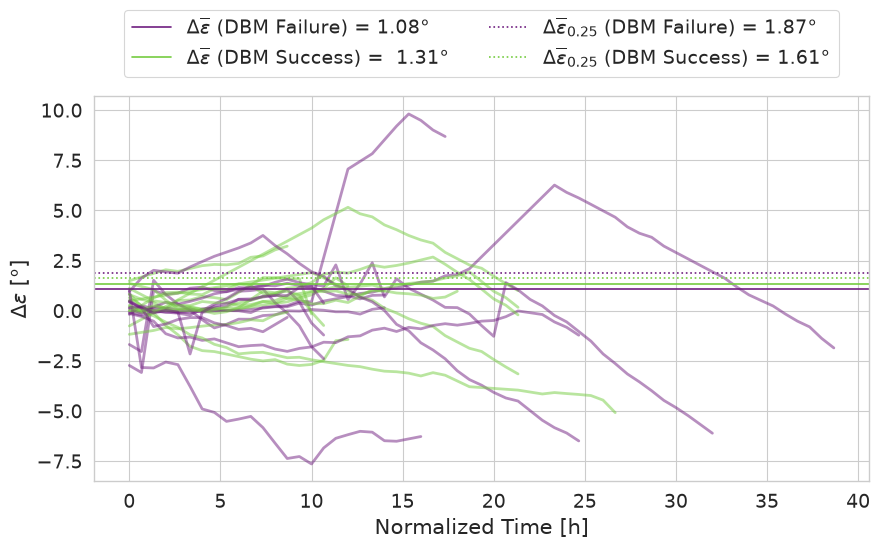

In [24]:
plot_abs = False
# Create a figure and plot the line on it
mean_abs_diff_fail = uncorrected_results_df[(uncorrected_results_df['DBM_status'] == 'Failure') & (uncorrected_results_df['DBM_status_corrected'] == 'Success')]['mean_abs_difference_elongation'].mean()
mean_abs_diff_success = uncorrected_results_df[uncorrected_results_df['DBM_status'] == 'Success']['mean_abs_difference_elongation'].mean()

mean_diff_fail = uncorrected_results_df[(uncorrected_results_df['DBM_status'] == 'Failure') & (uncorrected_results_df['DBM_status_corrected'] == 'Success')]['mean_difference_elongation'].abs().mean()
mean_diff_success = uncorrected_results_df[uncorrected_results_df['DBM_status'] == 'Success']['mean_difference_elongation'].abs().mean()

perc_track = 0.25
mean_abs_diff_fail_last_points = []
mean_abs_diff_success_last_points = []

mean_diff_fail_last_points = []
mean_diff_success_last_points = []
for row_num, row in uncorrected_results_df.iterrows():
    num_pts = int(len(row['abs_difference_elongation_whole_track'])*perc_track)
    if row['DBM_status'] == 'Failure':
        mean_abs_diff_fail_last_points.append(np.mean(row['abs_difference_elongation_whole_track'][-num_pts:]))
        mean_diff_fail_last_points.append(np.abs(np.mean(row['difference_elongation_whole_track'][-num_pts:])))
    else:
        mean_abs_diff_success_last_points.append(np.mean(row['abs_difference_elongation_whole_track'][-num_pts:]))
        mean_diff_success_last_points.append(np.abs(np.mean(row['difference_elongation_whole_track'][-num_pts:])))

fig1, ax1 = plt.subplots(figsize=(10, 5))
if plot_abs:
    chosen_difference = difference_whole_track_abs
else:
    chosen_difference = difference_whole_track

for num, entry in enumerate(chosen_difference):
    if uncorrected_results_df.iloc[num]['DBM_status_corrected'] == 'Failure':
        continue
    else:
        ax1.plot(normalized_time[num], entry, alpha=0.5, color=purple_palette[2] if (uncorrected_results_df.iloc[num]['DBM_status'] == 'Failure' and uncorrected_results_df.iloc[num]['DBM_status_corrected'] == 'Success') else green_palette[2], ls='-', lw=2)

ax1.set_xlabel('Normalized Time [h]', fontsize=label_fontsize)


if plot_abs:

    ax1.set_ylabel('|$\Delta \epsilon$| [°]', fontsize=label_fontsize)

    ax1.axhline(mean_abs_diff_fail, color=purple_palette[2], linestyle='--', label=f'|$\Delta \overline{{\epsilon}}$| (DBM Failure) = {mean_abs_diff_fail:.2f}°')
    ax1.axhline(mean_abs_diff_success, color=green_palette[2], linestyle='--', label=f'|$\Delta \overline{{\epsilon}}$| (DBM Success) =  {mean_abs_diff_success:.2f}°')

    ax1.axhline(np.mean(mean_abs_diff_fail_last_points), color=purple_palette[2], linestyle=':', label=f'|$\Delta \overline{{\epsilon}}_{{0.25}}$| (DBM Failure) = {np.mean(mean_abs_diff_fail_last_points):.2f}°')
    ax1.axhline(np.mean(mean_abs_diff_success_last_points), color=green_palette[2], linestyle=':', label=f'|$\Delta \overline{{\epsilon}}_{{0.25}}$| (DBM Success) = {np.mean(mean_abs_diff_success_last_points):.2f}°')

else:
    ax1.set_ylabel('$\Delta \epsilon$ [°]', fontsize=label_fontsize)

    ax1.axhline(mean_diff_fail, color=purple_palette[2], linestyle='-', label=f'$\Delta \overline{{\epsilon}}$ (DBM Failure) = {mean_diff_fail:.2f}°')
    ax1.axhline(mean_diff_success, color=green_palette[2], linestyle='-', label=f'$\Delta \overline{{\epsilon}}$ (DBM Success) =  {mean_diff_success:.2f}°')

    ax1.axhline(np.mean(mean_diff_fail_last_points), color=purple_palette[2], linestyle=':', label=f'$\Delta \overline{{\epsilon}}_{{0.25}}$ (DBM Failure) = {np.mean(mean_diff_fail_last_points):.2f}°')
    ax1.axhline(np.mean(mean_diff_success_last_points), color=green_palette[2], linestyle=':', label=f'$\Delta \overline{{\epsilon}}_{{0.25}}$ (DBM Success) = {np.mean(mean_diff_success_last_points):.2f}°')
    
ax1.legend(fontsize=ticks_fontsize, bbox_to_anchor=(0.5, 1.25),
           loc="upper center", ncols=2, frameon=True)
# change font size of x and y tick labels
ax1.tick_params(axis='both', which='major', labelsize=ticks_fontsize)
#plt.show()
plt.savefig(f"{save_plot_paper_path}elongation_difference_tracks_abs_{plot_abs}.pdf", dpi=300, bbox_inches='tight')
# plot suggests that tracks for which DBM fitting fails have a larger MAE in elongation (= difference between corrected and raw tracks), particularly at the end of the track

In [25]:
unique_labels = dfs['label'].unique()
arrival_error_mean_corrected = []
arrival_error_mean_uncorrected = []
track_deviation = []

for label in unique_labels:
    subset = dfs[dfs['label'] == label]
    cme_id = label.split('/')[0][:-1]
    feature_code = label.split('/')[1][1:]

    corresponding_uncorrected = uncorrected_results_df[(uncorrected_results_df['cmeID_elevo'] == cme_id) &
                                                        (uncorrected_results_df['featureCode'] == feature_code)]
    subset_corrected = subset[subset['source'] == elevohi_corrected_label]
    subset_uncorrected = subset[subset['source'] == elevohi_uncorrected_label]

    if len(subset_corrected) > 0 and len(subset_uncorrected) > 0:
        arrival_error_mean_corrected.append(subset_corrected['err_mean'])
        arrival_error_mean_uncorrected.append(subset_uncorrected['err_mean'])

        track_deviation.append(corresponding_uncorrected['mean_abs_difference_elongation'].values[0])

# Additional Metrics

In [26]:
dfs = pd.concat([
    prepare(elevohi_results_uncorrected_df, elevohi_uncorrected_label),
    prepare(elevohi_results_corrected_df,   elevohi_corrected_label),
    prepare(elevo_results_df,               elevo_label),
], ignore_index=True)

In [27]:
# get only errors of of events where predicitons are present from all three sources

unique_labels = dfs['label'].unique()
error_common_elevo = []
error_common_elevohi_uncorrected = []
error_common_elevohi_corrected = []

for label in unique_labels:
    subset = dfs[dfs['label'] == label]

    if len(subset) != 3:
        continue
    else:
        subset_elevo = subset[subset['source'] == 'ELEvo']
        error_common_elevo.append([subset_elevo['err_mean'].values[0], subset_elevo['err_min'].values[0], subset_elevo['err_max'].values[0]])

        subset_elevohi_uncorrected = subset[subset['source'] == elevohi_uncorrected_label]
        error_common_elevohi_uncorrected.append([subset_elevohi_uncorrected['err_mean'].values[0], subset_elevohi_uncorrected['err_min'].values[0], subset_elevohi_uncorrected['err_max'].values[0]])

        subset_elevohi_corrected = subset[subset['source'] == elevohi_corrected_label]
        error_common_elevohi_corrected.append([subset_elevohi_corrected['err_mean'].values[0], subset_elevohi_corrected['err_min'].values[0], subset_elevohi_corrected['err_max'].values[0]])


In [28]:
print("% TABLE 1 %")

total_sum = plot_df[(plot_df['featureCode'] == 'SH') & (plot_df['category'] == cat_features)]['count'].sum() + plot_df[(plot_df['featureCode'] == 'LE') & (plot_df['category'] == cat_features)]['count'].sum()

print(f"\\newcommand\\tabOneTotalSH{{{plot_df[(plot_df['featureCode'] == 'SH') & (plot_df['category'] == cat_features)]['count'].sum()}}}")
print(f"\\newcommand\\tabOneTotalLE{{{plot_df[(plot_df['featureCode'] == 'LE') & (plot_df['category'] == cat_features)]['count'].sum()}}}")
print(f"\\newcommand\\tabOneTotalSum{{{total_sum}}}")
print(f"\\newcommand\\tabOneTotalUnique{{{plot_df[(plot_df['featureCode'] == 'total') & (plot_df['category'] == cat_unique_cmes)]['count'].sum()}}}")
print("\n")
print(f"\\newcommand\\tabOneHasArrivalSH{{{plot_df[(plot_df['featureCode'] == 'SH') & (plot_df['category'] == cat_features_arrival)]['count'].sum()}}}")
print(f"\\newcommand\\tabOneHasArrivalLE{{{plot_df[(plot_df['featureCode'] == 'LE') & (plot_df['category'] == cat_features_arrival)]['count'].sum()}}}")
print(f"\\newcommand\\tabOneHasArrivalSum{{{plot_df[(plot_df['featureCode'] == 'SH') & (plot_df['category'] == cat_features_arrival)]['count'].sum() + plot_df[(plot_df['featureCode'] == 'LE') & (plot_df['category'] == cat_features_arrival)]['count'].sum()}}}")
print(f"\\newcommand\\tabOneHasArrivalUnique{{{plot_df[(plot_df['featureCode'] == 'total') & (plot_df['category'] == cat_unique_cmes_arrival)]['count'].sum()}}}")
print("\n")
print(f"\\newcommand\\tabOneArrivalPossibleSH{{{len(elevo_results_df[elevo_results_df['featureCode'] == 'SH'])}}}")
print(f"\\newcommand\\tabOneArrivalPossibleLE{{{len(elevo_results_df[elevo_results_df['featureCode'] == 'LE'])}}}")
print(f"\\newcommand\\tabOneArrivalPossibleSum{{{len(elevo_results_df)}}}")
print(f"\\newcommand\\tabOneArrivalPossibleUnique{{{len(elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False))}}}")
print("\n")
print(f"\\newcommand\\tabOneArrivalPossibleAndHasArrivalSH{{{len(elevo_results_df[(elevo_results_df['featureCode'] == 'SH') & (~pd.isna(elevo_results_df['L1_ist_obs [UT]']))])}}}")
print(f"\\newcommand\\tabOneArrivalPossibleAndHasArrivalLE{{{len(elevo_results_df[(elevo_results_df['featureCode'] == 'LE') & (~pd.isna(elevo_results_df['L1_ist_obs [UT]']))])}}}")
print(f"\\newcommand\\tabOneArrivalPossibleAndHasArrivalSum{{{len(elevo_results_df[~pd.isna(elevo_results_df['L1_ist_obs [UT]'])])}}}")
print(f"\\newcommand\\tabOneArrivalPossibleAndHasArrivalUnique{{{len(elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)[~pd.isna(elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)['L1_ist_obs [UT]'])])}}}")
print("\n")
print("% Table 2%")
print(f"\\newcommand\\tabTwoStrudlNoTracked{{{len(uncorrected_results_df)}}}")
print(f"\\newcommand\\tabTwoStrudlAvgMaxE{{{uncorrected_max_el:.2f}}}")
print(f"\\newcommand\\tabTwoStrudlAvgDeltaTStart{{{uncorrected_delta_time_215:.2f}}}")
print(f"\\newcommand\\tabTwoStrudlNoFailedFits{{{len(uncorrected_results_df)-len(elevohi_results_uncorrected_df)}}}")
print(f"\\newcommand\\tabTwoStrudlAvgMaxEFailedFits{{{np.nanmean(max_fitted_uncorrected_failed):.2f}}}")
print(f"\\newcommand\\tabTwoStrudlAvgMaxESuccessfulFits{{{np.nanmean(max_fitted_uncorrected_succeeded):.2f}}}")
print("\n")
print(f"\\newcommand\\tabTwoManualNoTracked{{{len(corrected_results_df)}}}")
print(f"\\newcommand\\tabTwoManualAvgMaxE{{{corrected_max_el:.2f}}}")
print(f"\\newcommand\\tabTwoManualAvgDeltaTStart{{{corrected_delta_time_215:.2f}}}")
print(f"\\newcommand\\tabTwoManualNoFailedFits{{{len(corrected_results_df)-len(elevohi_results_corrected_df)}}}")
print(f"\\newcommand\\tabTwoManualAvgMaxEFailedFits{{{np.nanmean(max_fitted_corrected_failed):.2f}}}")
print(f"\\newcommand\\tabTwoManualAvgMaxESuccessfulFits{{{np.nanmean(max_fitted_corrected_succeeded):.2f}}}")
print("\n")
print("% TABLE 3 %")
print(f"\\newcommand\\tabThreeELEvoNoValid{{{len(elevo_results_df[~pd.isna(elevo_results_df['L1_ist_obs [UT]'])])}}}")
print(f"\\newcommand\\tabThreeELEvoAvgMinDeltaT{{{mean_abs_dt_elevo_min:.2f}}}")
print(f"\\newcommand\\tabThreeELEvoAvgMaxDeltaT{{{mean_abs_dt_elevo_max:.2f}}}")
print(f"\\newcommand\\tabThreeELEvoAvgMeanDeltaT{{{mean_abs_dt_elevo:.2f}}}")
print(f"\\newcommand\\tabThreeELEvoAvgMinDeltaTStd{{{std_mean_abs_dt_elevo_min:.2f}}}")
print(f"\\newcommand\\tabThreeELEvoAvgMaxDeltaTStd{{{std_mean_abs_dt_elevo_max:.2f}}}")
print(f"\\newcommand\\tabThreeELEvoAvgMeanDeltaTStd{{{std_mean_abs_dt_elevo:.2f}}}")
print("\n")
print(f"\\newcommand\\tabThreeStrudlNoValid{{{len(elevohi_results_uncorrected_df)}}}")
print(f"\\newcommand\\tabThreeStrudlAvgMinDeltaT{{{mean_abs_dt_elevohi_uncorrected_min:.2f}}}")
print(f"\\newcommand\\tabThreeStrudlAvgMaxDeltaT{{{mean_abs_dt_elevohi_uncorrected_max:.2f}}}")
print(f"\\newcommand\\tabThreeStrudlAvgMeanDeltaT{{{mean_abs_dt_elevohi_uncorrected:.2f}}}")
print(f"\\newcommand\\tabThreeStrudlAvgMinDeltaTStd{{{std_mean_abs_dt_elevohi_uncorrected_min:.2f}}}")
print(f"\\newcommand\\tabThreeStrudlAvgMaxDeltaTStd{{{std_mean_abs_dt_elevohi_uncorrected_max:.2f}}}")
print(f"\\newcommand\\tabThreeStrudlAvgMeanDeltaTStd{{{std_mean_abs_dt_elevohi_uncorrected:.2f}}}")
print("\n")
print(f"\\newcommand\\tabThreeManualNoValid{{{len(elevohi_results_corrected_df)}}}")
print(f"\\newcommand\\tabThreeManualAvgMinDeltaT{{{mean_abs_dt_elevohi_corrected_min:.2f}}}")
print(f"\\newcommand\\tabThreeManualAvgMaxDeltaT{{{mean_abs_dt_elevohi_corrected_max:.2f}}}")
print(f"\\newcommand\\tabThreeManualAvgMeanDeltaT{{{mean_abs_dt_elevohi_corrected:.2f}}}")
print(f"\\newcommand\\tabThreeManualAvgMinDeltaTStd{{{std_mean_abs_dt_elevohi_corrected_min:.2f}}}")
print(f"\\newcommand\\tabThreeManualAvgMaxDeltaTStd{{{std_mean_abs_dt_elevohi_corrected_max:.2f}}}")
print(f"\\newcommand\\tabThreeManualAvgMeanDeltaTStd{{{std_mean_abs_dt_elevohi_corrected:.2f}}}")
print("\n")
print("% OTHER %")
print(f"\\newcommand\\deltaTMeanAllValidELEvo{{{np.mean([abs(x[0]) for x in error_common_elevo]):.2f}}}")
print(f"\\newcommand\\deltaTMeanAllValidStrudl{{{np.mean([abs(x[0]) for x in error_common_elevohi_uncorrected]):.2f}}}")
print(f"\\newcommand\\deltaTMeanAllValidManual{{{np.mean([abs(x[0]) for x in error_common_elevohi_corrected]):.2f}}}")
print("\n")
print(f"\\newcommand\\deltaTMinAllValidELEvo{{{np.mean([abs(x[1]) for x in error_common_elevo]):.2f}}}")
print(f"\\newcommand\\deltaTMinAllValidStrudl{{{np.mean([abs(x[1]) for x in error_common_elevohi_uncorrected]):.2f}}}")
print(f"\\newcommand\\deltaTMinAllValidManual{{{np.mean([abs(x[1]) for x in error_common_elevohi_corrected]):.2f}}}")
print("\n")
print(f"\\newcommand\\deltaTMaxAllValidELEvo{{{np.mean([abs(x[2]) for x in error_common_elevo]):.2f}}}")
print(f"\\newcommand\\deltaTMaxAllValidStrudl{{{np.mean([abs(x[2]) for x in error_common_elevohi_uncorrected]):.2f}}}")
print(f"\\newcommand\\deltaTMaxAllValidManual{{{np.mean([abs(x[2]) for x in error_common_elevohi_corrected]):.2f}}}")
print("\n")
print(f"\\newcommand\\deltaEDBMFailure{{{np.mean(mean_diff_fail):.2f}}}")
print(f"\\newcommand\\deltaEDBMSuccess{{{np.mean(mean_diff_success):.2f}}}")
print(f"\\newcommand\\deltaEDBMFailEnd{{{np.mean(mean_diff_fail_last_points):.2f}}}")
print(f"\\newcommand\\deltaEDBMSuccessEnd{{{np.mean(mean_diff_success_last_points):.2f}}}")
print("\n")
print(f"\\newcommand\\StrudlNoTrackedUnique{{{len(uncorrected_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False))}}}")
print(f"\\newcommand\\StrudlNoTrackedHasArrival{{{len(uncorrected_results_df[uncorrected_results_df['L1_ist_obs'].notna()])}}}")
print(f"\\newcommand\\StrudlNoTrackedUniqueHasArrival{{{len(uncorrected_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)[uncorrected_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)['L1_ist_obs'].notna()])}}}")
print("\n")
print(f"\\newcommand\\StrudlMiss{{{len(elevo_results_df[~pd.isna(elevo_results_df['L1_ist_obs [UT]'])]) - len(uncorrected_results_df[uncorrected_results_df['L1_ist_obs'].notna()])}}}")
print(f"\\newcommand\\StrudlMissUnique{{{len(elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)[~pd.isna(elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)['L1_ist_obs [UT]'])]) - len(uncorrected_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)[uncorrected_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)['L1_ist_obs'].notna()])}}}")
print("\n")

false_positives_strudl_unqiue = len(uncorrected_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)[uncorrected_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)['L1_ist_obs'].isna()])
true_positives_strudl_unique = len(uncorrected_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)[uncorrected_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)['L1_ist_obs'].notna()])
fdr_strudl = false_positives_strudl_unqiue / (false_positives_strudl_unqiue + true_positives_strudl_unique)
print(f"\\newcommand\\StrudlFalseDetectionRate{{{fdr_strudl*100:.1f}}}")

false_positives_elevo_unique = len(elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)[elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)['L1_ist_obs [UT]'].isna()])
true_positives_elevo_unique = len(elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)[elevo_results_df.drop_duplicates(subset=['cmeID_elevo'], inplace=False)['L1_ist_obs [UT]'].notna()])
fdr_elevo = false_positives_elevo_unique / (false_positives_elevo_unique + true_positives_elevo_unique)
print(f"\\newcommand\\ELEvoFalseDetectionRate{{{fdr_elevo*100:.1f}}}")
print("\n")
print(f"\\newcommand\\MeanVinitStrudlDetected{{{np.mean(vinit_detected):.0f}}}")
print(f"\\newcommand\\MeanVinitStrudlNotDetected{{{np.nanmean(vinit_not_detected):.0f}}}")
print("\n")
print(f"\\newcommand\\CommonFits{{{len(error_common_elevo)}}}")

% TABLE 1 %
\newcommand\tabOneTotalSH{86}
\newcommand\tabOneTotalLE{1566}
\newcommand\tabOneTotalSum{1652}
\newcommand\tabOneTotalUnique{1566}


\newcommand\tabOneHasArrivalSH{25}
\newcommand\tabOneHasArrivalLE{89}
\newcommand\tabOneHasArrivalSum{114}
\newcommand\tabOneHasArrivalUnique{89}


\newcommand\tabOneArrivalPossibleSH{33}
\newcommand\tabOneArrivalPossibleLE{66}
\newcommand\tabOneArrivalPossibleSum{99}
\newcommand\tabOneArrivalPossibleUnique{83}


\newcommand\tabOneArrivalPossibleAndHasArrivalSH{22}
\newcommand\tabOneArrivalPossibleAndHasArrivalLE{43}
\newcommand\tabOneArrivalPossibleAndHasArrivalSum{65}
\newcommand\tabOneArrivalPossibleAndHasArrivalUnique{52}


% Table 2%
\newcommand\tabTwoStrudlNoTracked{47}
\newcommand\tabTwoStrudlAvgMaxE{16.73}
\newcommand\tabTwoStrudlAvgDeltaTStart{0.41}
\newcommand\tabTwoStrudlNoFailedFits{26}
\newcommand\tabTwoStrudlAvgMaxEFailedFits{16.61}
\newcommand\tabTwoStrudlAvgMaxESuccessfulFits{16.88}


\newcommand\tabTwoManualNoTracked{99}
\newc